In [80]:
import os
import sys
import mne
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

sys.path.append('../..')

from data.data_configs import *
from data.data_loader import DataLoader
from data.data_utils import transform_eeg_time_to_ms

In [81]:
def epoch_stimulus_eeg(subject: str, pre_ms: int = 200, post_ms: int = 500, eeg_dir: str = EEG_DIR, summary_path: str = None):
    
    # Load EEG
    raw, data, times, channel_names = DataLoader.load_eeg(subject, eeg_dir=eeg_dir)
    fs = raw.info["sfreq"]
    times_ms_full = transform_eeg_time_to_ms(times)

    # Load summary table
    summary_df = pd.read_csv(summary_path)
    summary_df = summary_df[summary_df['subject'] == subject]

    X_segments = []

    n_samples = int((pre_ms + post_ms) * fs / 1000)

    for _, row in summary_df.iterrows():
        onset_ms = row['eeg_stimulus_onset']  # EEG-aligned stimulus onset
        # Find indices
        i0 = max(0, np.searchsorted(times_ms_full, onset_ms - pre_ms))
        i1 = min(data.shape[1], i0 + n_samples)  # ensure fixed-length epoch
        if i1 - i0 != n_samples:
            continue  # skip epochs that would be too short at the edges
        X_segments.append(data[:, i0:i1])

    X_segments = np.array(X_segments)
    times_ms = np.arange(n_samples) * (1000.0 / fs) - pre_ms

    return X_segments, times_ms, channel_names

In [82]:
def baseline_correct_epochs(segments: np.ndarray, fs: float, pre_ms: int, baseline_window_ms: int = 300):
    """Apply per-epoch baseline correction using the 500 ms before stimulus onset."""
    # Always use the window from -500 ms to 0 ms relative to onset
    start_idx = int((pre_ms - baseline_window_ms) * fs / 1000)
    end_idx = int(pre_ms * fs / 1000)
    corrected = np.empty_like(segments)
    for i, seg in enumerate(segments):
        # Ensure indices are within bounds
        if start_idx < 0 or end_idx > seg.shape[1] or start_idx >= end_idx:
            baseline = np.zeros((seg.shape[0], 1))
        else:
            baseline = seg[:, start_idx:end_idx].mean(axis=1, keepdims=True)
        corrected[i] = seg - baseline
    return corrected


In [83]:
# --- ERP plotting with CI ---
def plot_erp_ci(time_ms, erp_data, channels_to_plot, ch_names):
    """Plot ERP with shaded CI for selected channels."""
    ch_idx = [ch_names.index(ch) for ch in channels_to_plot if ch in ch_names]
    if not ch_idx:
        raise ValueError("Channels not found in ch_names")

    avg_channels = np.mean(erp_data[:, ch_idx, :], axis=1)  # epochs x timepoints
    mean_signal = np.mean(avg_channels, axis=0)
    sem = np.std(avg_channels, axis=0, ddof=1) / np.sqrt(avg_channels.shape[0])
    z = 1.96  # 95% CI

    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(time_ms, mean_signal, color='#D62728', label='ERP', linewidth=2)
    ax.fill_between(time_ms, mean_signal - sem*z, mean_signal + sem*z, color='#D62728', alpha=0.2)
    ax.axvline(0, color='black', linestyle='--', alpha=0.7, label='Stimulus onset')

    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Amplitude (μV)')
    ax.set_title(f"ERP: {', '.join(channels_to_plot)}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [84]:
# --- Run epoching across subjects ---
def run_stimulus_erp(subjects, pre_ms=200, post_ms=1000, summary_path=None, channels_of_interest=['Pz','P3','P4']):
    all_epochs = []

    for subj in tqdm(subjects, desc="Epoching EEG"):
        # Use your provided function
        X, time_axis, ch_names = epoch_stimulus_eeg(subj, pre_ms=pre_ms, post_ms=post_ms, summary_path=summary_path)
        fs = len(time_axis) / ((pre_ms + post_ms)/1000)  # approximate sampling rate
        X = baseline_correct_epochs(X, fs, pre_ms)
        all_epochs.append(X)

    # Concatenate epochs across subjects
    all_epochs = np.concatenate(all_epochs, axis=0)  # epochs x channels x timepoints

    # Plot grand-average ERP
    plot_erp_ci(time_axis, all_epochs, channels_of_interest, ch_names)
    return all_epochs, time_axis, ch_names


In [85]:
summary_path = os.path.join(SELECTED_ET_DATA_DIR, "fixation_summary_all.csv")

Epoching EEG: 100%|██████████| 13/13 [00:30<00:00,  2.38s/it]


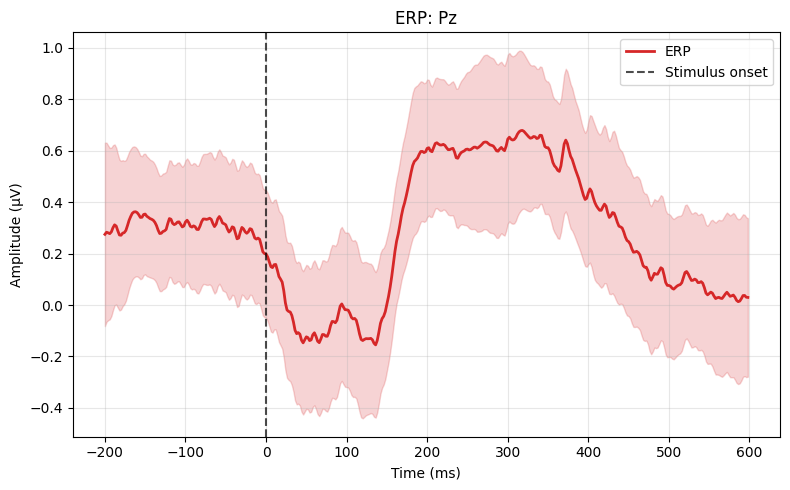

In [86]:
cannels = ['Pz']
subjects = SUBJECTS
all_epochs, time_axis, ch_names = run_stimulus_erp(subjects, pre_ms=200, post_ms=600, summary_path=summary_path, channels_of_interest=cannels)


Epoching EEG:   0%|          | 0/13 [00:00<?, ?it/s]

Epoching EEG: 100%|██████████| 13/13 [00:24<00:00,  1.85s/it]


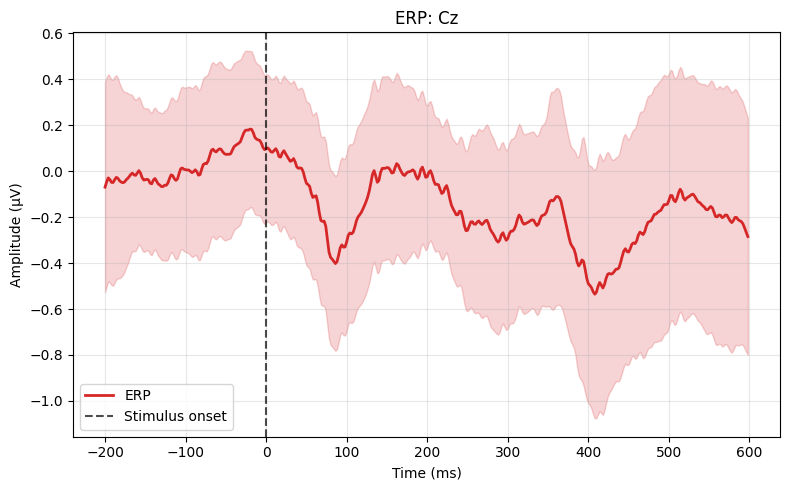

In [87]:
cannels = ['Cz']
subjects = SUBJECTS
all_epochs, time_axis, ch_names = run_stimulus_erp(subjects, pre_ms=200, post_ms=600, summary_path=summary_path, channels_of_interest=cannels)


Epoching EEG:   0%|          | 0/13 [00:00<?, ?it/s]

Epoching EEG: 100%|██████████| 13/13 [00:27<00:00,  2.11s/it]


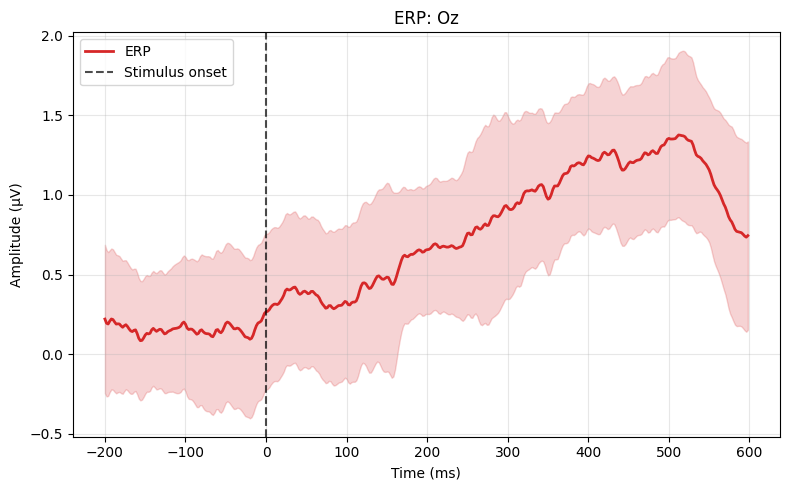

In [88]:
cannels = ['Oz']
subjects = SUBJECTS
all_epochs, time_axis, ch_names = run_stimulus_erp(subjects, pre_ms=200, post_ms=600, summary_path=summary_path, channels_of_interest=cannels)


Epoching EEG: 100%|██████████| 13/13 [00:25<00:00,  1.96s/it]


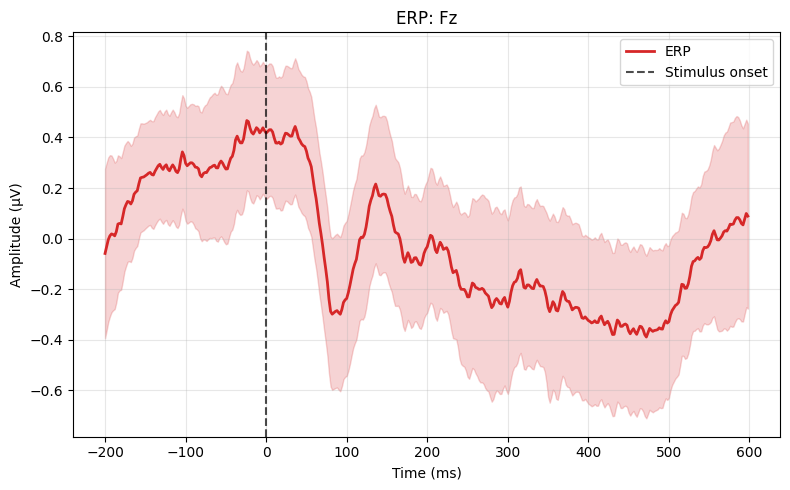

In [90]:
cannels = ['Fz']
subjects = SUBJECTS
all_epochs, time_axis, ch_names = run_stimulus_erp(subjects, pre_ms=200, post_ms=600, summary_path=summary_path, channels_of_interest=cannels)
